# M04 概覽 | Conv + BN 折疊：PTQ 在 prepare 折，QAT 在 convert 才折

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m04_conv_bn_folding/00_overview.ipynb)

模型裡幾乎每個 conv 後面都接著 BatchNorm。部署時 BN 不會單獨跑：它的運算可以整個折進前面的 conv。
這一章看 PT2E 在哪一步折、怎麼折，以及 QAT 為什麼不能照 PTQ 的方式折。
後面三本 notebook（M04-1～M04-3）逐一動手驗證。

QAT 的部分建議先讀部落格〈[Convolution 與 BatchNorm 的融合大法](https://bobondemon.github.io/2025/05/04/Convolution-%E8%88%87-BatchNorm-%E7%9A%84%E8%9E%8D%E5%90%88%E5%A4%A7%E6%B3%95/)〉。
它從推論時的折疊講起，接著說明 QAT 時 fake quant 該怎麼插、為什麼，最後看 PyTorch 的實作。
本章的 QAT 段落就是把那篇文章的結論，對到 PT2E 產生的圖上。

In [ ]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m04_conv_bn_folding")

In [1]:
#| echo: false
import copy

import torch

from common.models import ConvBnReLU, example_inputs
from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, prepare_qat_pt2e, quiet
from common.viz import draw_stages

quiet()
_ = torch.manual_seed(0)

model = ConvBnReLU(3, 8).train()  # 先跑幾個 batch，讓 BN 有真實的 running stats
with torch.no_grad():
    for _ in range(5):
        model(torch.randn(16, 3, 16, 16) * 2 + 1)
_ = model.eval()

## 為什麼要折 BN

eval 模式的 BN 只是對每個 channel 做一次乘加。如果它的輸入就是 conv 的輸出，這個乘加可以預先算進 conv 的 weight 與 bias：
部署時少一個 op，量化時也少一個要量化的 tensor，而且量化的是部署時真正用到的 weight。

舊的 eager／FX 量化把 Conv + BN + ReLU 換成一個 `ConvBnReLU2d` 模組。PT2E 的圖上沒有這種模組，`conv2d`、`batch_norm`、`relu` 都是獨立的 node。
所以 PT2E 的「融合」拆成兩件事：

- **BN 折疊**：把 BN 的運算折進 conv 的 weight 與 bias。這是本章的主題。
- **conv 與 relu 之間不放量化點**：Quantizer 把輸出標籤貼在 relu、不貼在 conv（M03-2 A）。這件事在 M03 已經講過，本章只在 M04-1 D 段看它在 convert 之後的樣子。

這一章回答三個問題：

| 問題 | 一句話的答案 | 動手驗證 |
|---|---|---|
| PTQ 的 BN 什麼時候、怎麼折？ | `prepare_pt2e` 一開始就折，weight、bias 換成式 (1)(2) | M04-1 |
| QAT 為什麼不能這樣折，改做什麼？ | BN 要繼續用 batch 統計訓練，所以留著；另外折一份給 weight 的 fake quant，convert 時才真的折 | M04-2 |
| QAT 的 fake quant 為什麼這樣插？PT2E 用的是哪一種做法？ | 量化「用 EMA 統計折過的 weight」，再用 BN 還原成 batch 統計；PT2E 用 PyTorch 的近似版，不是白皮書的慢版 | M04-2、M04-3 |

## 先看一個例子：conv → bn → relu

同一個 conv + BN + relu（conv 沒有 bias），左邊是 export 的圖，右邊是 `prepare_pt2e` 之後。請看三件事：

- `batch_norm` 在 prepare 之後消失了（虛線框）。
- conv 的 weight 名字沒變，但值已經換成折過的；底下多了一個原本沒有的 `conv_weight_bias`。
- prepare 之後的 observer（綠框）量化的是這個折過的 weight。

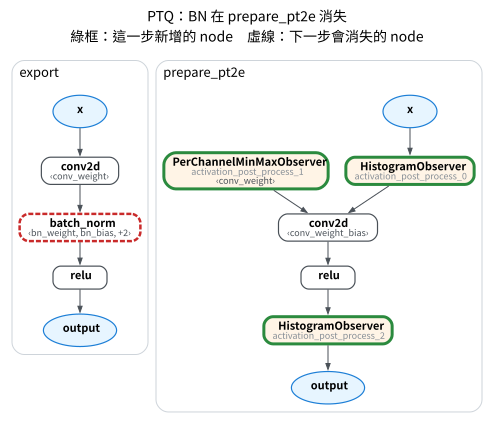

In [2]:
#| echo: false
gm = export_module(model, example_inputs())
prepared = prepare_pt2e(copy.deepcopy(gm), get_xnnpack_quantizer(is_per_channel=True)[0])
draw_stages([(gm, "export"), (prepared, "prepare_pt2e")], title="PTQ：BN 在 prepare_pt2e 消失")

## 定義

### BN 折疊

eval 模式的 BN 對每個 channel 做 $\mathrm{BN}(y) = \gamma \dfrac{y - \mu}{\sqrt{\sigma^2 + \varepsilon}} + \beta$：
$\mu$、$\sigma^2$ 是訓練時累積的 running mean／var，$\gamma$、$\beta$ 是 BN 的 weight／bias。
把 conv 的輸出 $y = W * x + b$ 代進去，整理成另一個 conv，weight 與 bias 是：

$$
W_{\text{fold}} = W \cdot \frac{\gamma}{\sqrt{\sigma^2+\varepsilon}} \tag{1}
$$

$$
b_{\text{fold}} = \beta + (b - \mu)\,\frac{\gamma}{\sqrt{\sigma^2+\varepsilon}} \tag{2}
$$

乘法是逐 output channel 的：第 $k$ 個 output channel 的 weight 都乘上 $\gamma_k / \sqrt{\sigma_k^2+\varepsilon}$。
這只是代數重排，折完的 fp32 輸出和原本相同。用上面例子的 BN 參數手算，和 torchao 折出來的比：

In [3]:
bn = model.bn
assert bn.running_mean is not None and bn.running_var is not None
k = bn.weight / torch.sqrt(bn.running_var + bn.eps)
w_fold = model.conv.weight * k.reshape(-1, 1, 1, 1)  # 式 (1)
b_fold = bn.bias - bn.running_mean * k  # 式 (2)，這個 conv 沒有 bias（b = 0）
same_w = torch.allclose(prepared.get_parameter("conv.weight"), w_fold, atol=1e-6)
same_b = torch.allclose(getattr(prepared.get_submodule("conv"), "weight_bias"), b_fold, atol=1e-6)
print(f"式 (1) 與 torchao 折出的 weight 相同？ {same_w}；式 (2) 與 bias 相同？ {same_b}")
assert same_w and same_b

式 (1) 與 torchao 折出的 weight 相同？ True；式 (2) 與 bias 相同？ True


### PTQ 與 QAT：BN 在哪一步折

| | PTQ（`prepare_pt2e`） | QAT（`prepare_qat_pt2e`） |
|---|---|---|
| prepare 之後的 BN | 已折進 conv，圖上消失 | 還在，訓練時用當下 batch 的統計 |
| weight 量化的對象 | 式 (1) 折完的 weight | 另外算一份 $W \cdot s$ 給 fake quant，等於式 (1) |
| BN 真正折掉的時間 | prepare 一開始，早於 Quantizer 的 `annotate` | `convert_pt2e` 時 |

QAT 為什麼不能在 prepare 時折：訓練中的 BN 要用**當下 batch** 的平均與變異數正規化，還要更新 running stats。
折掉就等於把 BN 凍結成 eval 模式，BN 不再訓練。

### QAT：weight 的 fake quant 該量化哪一份 weight

以下的推理整理自上面的部落格文章，原始出處是 Google 的量化白皮書
（R. Krishnamoorthi, *Quantizing deep convolutional networks for efficient inference: A whitepaper*, 2018）。
這裡 conv 沒有 bias；以下的 $\sigma$ 指標準差、已經包含 $\varepsilon$，也就是式 (1) 分母的 $\sqrt{\sigma^2+\varepsilon}$。

訓練時 BN 用這個 batch 的 $\mu_B$、$\sigma_B$，推論時用它們的 EMA（running stats）$\mu$、$\sigma$。
所以「折過的 weight」有兩個版本：

$$
W_{\text{train}} = \frac{\gamma W}{\sigma_B}, \qquad W_{\text{inf}} = \frac{\gamma W}{\sigma} \tag{3}
$$

$W_{\text{inf}}$ 就是式 (1)，部署時真正被量化成 int8 的 weight。weight 的 fake quant 有三個候選：

| fake quant 量化 | 問題 |
|---|---|
| $W$（沒折的 conv weight） | 部署時量化的是 $W_{\text{inf}}$，訓練看到的量化誤差和部署時不同 |
| $W_{\text{train}}$ | $\sigma_B$ 每個 batch 都在跳，量化的格子跟著跳，再加上 fake quant 的誤差，訓練不穩定（白皮書的實驗看到 loss 抖動） |
| $W_{\text{inf}}$ | EMA 變化慢，而且和部署時量化的 weight 相同 → **選這個** |

但 BN 訓練時要的是 batch 統計的效果。白皮書的做法是量化 $W_{\text{inf}}$，再乘一個**修正項** $\sigma / \sigma_B$ 還原成 $W_{\text{train}}$：

$$
y = \mathrm{conv}\big(\mathrm{fq}(x),\ \mathrm{fq}(W_{\text{inf}})\big) \cdot \frac{\sigma}{\sigma_B} + \Big(\beta - \frac{\gamma\,\mu_B}{\sigma_B}\Big) \tag{4}
$$

問題是 $\mu_B$、$\sigma_B$ 要從**沒量化**的 conv 輸出算，所以每一步要多算一次 conv。PyTorch 把它實作成 `_forward_slow`，以下稱**慢版**。

### PyTorch 的近似版：PT2E 用的就是這個

PyTorch eager QAT 預設的 `_forward_approximate` 省掉那一次 conv，`prepare_qat_pt2e` 插的子圖也是它：

$$
s = \frac{\gamma}{\sigma}, \qquad
y = \mathrm{BN}_{\text{batch}}\!\Big( \frac{\mathrm{conv}\big(\mathrm{fq}(x),\ \mathrm{fq}(W \cdot s)\big)}{s} \Big) \tag{5}
$$

- $W \cdot s = \gamma W / \sigma = W_{\text{inf}}$：fake quant 量化的正是上表選的那一份。
- **為什麼要除以 $s$**：$\mathrm{conv}(\cdot, W_{\text{inf}}) / s$ 約等於沒折 BN 的 conv 輸出，交給後面正常訓練的 BN，BN 就能從它算出 batch 統計 $\mu_B'$、$\sigma_B'$。
  把 BN 展開：$\gamma \dfrac{z/s - \mu_B'}{\sigma_B'} + \beta = z \cdot \dfrac{\sigma}{\sigma_B'} + \Big(\beta - \dfrac{\gamma\,\mu_B'}{\sigma_B'}\Big)$（$z$ 是量化 conv 的輸出），正好是式 (4) 的形式。
- 唯一的差別：$\mu_B'$、$\sigma_B'$ 取自**量化後**的 conv 輸出，慢版取自**沒量化**的。代價是 batch 統計混進了量化誤差，換來少一次 conv。

M04-2 把式 (5) 的每一項對到圖上的 node，M04-3 手寫兩個版本比數值。

## 用程式驗證：QAT 的 BN 在 convert 時才消失

同一個模型走 QAT：用 training IR export、`is_qat=True` 的 quantizer。prepare 之後 BN 還在，convert 之後才消失：

In [4]:
def has_bn(g):
    return any("batch_norm" in str(n.target) for n in g.graph.nodes)


qat_prepared = prepare_qat_pt2e(export_module(copy.deepcopy(model).train(), example_inputs(), train=True),
                                get_xnnpack_quantizer(is_per_channel=True, is_qat=True)[0])
with torch.no_grad():
    qat_prepared(torch.randn(16, 3, 16, 16) * 2 + 1)  # 讓 fake quant 的範圍有值
qat_converted = convert_pt2e(copy.deepcopy(qat_prepared))
print(f"QAT：prepare 之後有 batch_norm？ {has_bn(qat_prepared)}；convert 之後？ {has_bn(qat_converted)}")
assert has_bn(qat_prepared) and not has_bn(qat_converted)

QAT：prepare 之後有 batch_norm？ True；convert 之後？ False


## 小結與本章地圖

- PT2E 沒有 fused 模組；conv + BN 的融合就是把 BN 折進 conv 的 weight 與 bias（式 1、2）。
- PTQ 在 `prepare_pt2e` 一開始就折；QAT 保留 BN 訓練，用式 (5) 讓 fake quant 量化 $W_{\text{inf}}$，`convert_pt2e` 才真的折。
- 兩條路 convert 之後的圖相同，後端看不出差別。

| notebook | 回答的問題 |
|---|---|
| [M04-1 PTQ 的 BN 折疊](01_bn_folding_trace.ipynb) | BN 在哪一步消失、weight 與 bias 怎麼改寫；conv 與 relu 之間多一個量化點，convert 之後長什麼樣 |
| [M04-2 QAT 的 conv + BN](02_qat_graph_structure.ipynb) | 式 (5) 的每一項是圖上哪個 node、convert 時怎麼折、什麼情況下折不掉 |
| [M04-3 慢版與近似版](03_qat_vs_article.ipynb) | PT2E 的子圖是不是 `_forward_approximate`、和慢版差多少 |

這一章刻意跳過的：QAT 的訓練流程、什麼時候凍結 BN 與 observer（M06）；`FusedMovingAvgObsFakeQuantize` 算 scale 的坑（M06-3）。

## 參考資料

- [Convolution 與 BatchNorm 的融合大法](https://bobondemon.github.io/2025/05/04/Convolution-%E8%88%87-BatchNorm-%E7%9A%84%E8%9E%8D%E5%90%88%E5%A4%A7%E6%B3%95/)：BN 折疊的推導、QAT 時 fake quant 該怎麼插、PyTorch 的慢版與近似版（建議先讀）
- R. Krishnamoorthi, [Quantizing deep convolutional networks for efficient inference: A whitepaper](https://arxiv.org/abs/1806.08342), 2018：修正項 $\sigma/\sigma_B$ 的做法（即慢版）
- torchao 0.18 原始碼：
  [`utils.py`](https://github.com/pytorch/ao/blob/v0.18.0/torchao/quantization/pt2e/utils.py)（PTQ 的 `_fuse_conv_bn_`）、
  [`qat_utils.py`](https://github.com/pytorch/ao/blob/v0.18.0/torchao/quantization/pt2e/qat_utils.py)（QAT 的子圖與 convert 時的折疊）
- PyTorch 原始碼：[`conv_fused.py`](https://github.com/pytorch/pytorch/blob/main/torch/ao/nn/intrinsic/qat/modules/conv_fused.py)（eager QAT 的 `_forward_approximate` 與 `_forward_slow`）